# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
# cargar archivos

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [43]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [44]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [45]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [46]:
# revisar el número de filas y columnas de cada dataset

print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [47]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [48]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [49]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [50]:
# cantidad de nulos para users

print("Cantidad de valores nulos en users:")
print(users.isna().sum())
print("\nProporción de valores nulos en users:")
print(users.isna().mean())

Cantidad de valores nulos en users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos en users:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [51]:
# cantidad de nulos para usage

print("Cantidad de valores nulos en usage:")
print(usage.isna().sum())
print("\nProporción de valores nulos en usage:")
print(usage.isna().mean())

Cantidad de valores nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos en usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?




**(RESPUESTA)**

**Diagnóstico de valores nulos:**

* **Dataset `users` (4,000 registros):**
  * **`city` (469 nulos / 11.73%):** Se recomienda **mantener como nulos** (o etiquetar como `"unknown"`), ya que imputar una ciudad aleatoria distorsionaría el análisis geográfico.
  * **`churn_date` (3,534 nulos / 88.35%):** Se recomienda **ignorar / dejar como nulos**, puesto que un valor ausente significa que el cliente sigue activo y no ha cancelado el servicio.

* **Dataset `usage` (40,000 registros):**
  * **`date` (50 nulos / 0.125%):** Al representar menos del 1% de los datos, se pueden **dejar como nulos** (o eliminar si se requiere análisis temporal estricto) sin afectar la representatividad general.
  * **`duration` (22,076 nulos / 55.19%) y `length` (17,896 nulos / 44.74%):** Se recomienda **dejar como nulos**, ya que corresponden a valores faltantes estructurales (MAR): las llamadas (`call`) no tienen longitud de texto (`length`) y los mensajes (`text`) no tienen duración (`duration`).


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [52]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

** RESPUESTAS ** 

- La columna `user_id` contiene 4,000 identificadores únicos consecutivos que van desde `10000` hasta `13999`, sin valores nulos ni anomalías en su secuencia.
- La columna `age` presenta un valor mínimo inválido de `-999` (valor *sentinel*), el cual distorsiona a la baja la media (`33.74` años) y dispara la desviación estándar (`123.23`), mientras que el resto de los cuartiles (`32`, `47` y `63` años) y el máximo (`79` años) se encuentran dentro de rangos demográficos normales.

In [13]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...
** RESPUESTAS **
  - Las columnas `id` (de `1` a `40,000`) y `user_id` (de `10,000` a `13,999`) corresponden a identificadores enteros válidos, completos (40,000 registros) y sin valores atípicos ni *sentinels*.
- Las columnas `duration` (17,924 registros válidos; mediana de `3.50` min y máximo de `120` min) y `length` (22,104 registros válidos; mediana de `50` caracteres y máximo de `1,490`) no presentan valores negativos ni *sentinels* numéricos, aunque sí muestran valores máximos elevados hacia la derecha (outliers reales de uso intensivo) y valores nulos estructurales según el tipo de evento.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f"--- {col} ---")
    print(users[col].value_counts(dropna=False))
    print()


--- city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

--- plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` ...
- La columna `plan` ...


** RESPUESTAS **

  - La columna `city` contiene seis ciudades válidas de Colombia y México (`Bogotá`: 808, `CDMX`: 730, `Medellín`: 616, `GDL`: 450, `Cali`: 424 y `MTY`: 407), además de `469` valores nulos (`NaN`) y `96` registros con el carácter inválido `"?"` (valor *sentinel*).
- La columna `plan` está limpia y completa (4,000 registros), distribuida exclusivamente entre las dos categorías válidas del catálogo: `Basico` (`2,595` usuarios) y `Premium` (`1,405` usuarios).

In [21]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` ...

** RESPUESTAS ** 

- La columna `type` está completa (40,000 registros) y contiene únicamente dos categorías válidas sin errores tipográficos ni *sentinels*: `text` (`22,092` mensajes, 55.23%) y `call` (`17,908` llamadas, 44.77%).

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

** RESPUESTAS ** 
**Diagnóstico de valores inválidos o sentinels:**
- **Columnas afectadas:** Se detectaron valores *sentinel* únicamente en el dataset `users`: el valor numérico `-999` en la columna `age` y el carácter `"?"` (`96` registros) en la columna `city`. El dataset `usage` no presenta *sentinels*.
- **Acción recomendada:** Reemplazar `-999` en `age` por la mediana de las edades válidas para no sesgar los promedios, y sustituir `"?"` en `city` por valores nulos (`pd.NA`) para estandarizar los datos faltantes.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [22]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [23]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [24]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

** RESPUESTAS ** 

En `reg_date`, se observan registros distribuidos de forma uniforme entre `2022` (`1,314` usuarios), `2023` (`1,316` usuarios) y `2024` (`1,330` usuarios), pero aparecen `40` registros en el año `2026` (1% del total), lo cual constituye un error de captura o fecha imposible dado que los datos del proyecto llegan hasta `2024`.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

** ///// RESPUESTAS //// *** 

En `date`, la totalidad de los registros válidos (`39,950` eventos, 99.875%) corresponde exclusivamente al año `2024`, acompañados únicamente por los `50` valores nulos (`NaN`, 0.125%) identificados previamente, sin presencia de años futuros ni fuera de rango.  
Basaremos el análisis en estas fechas.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

** //////  RESPUESTAS /////**

**Diagnóstico de fechas fuera de rango:**
- **Años imposibles detectados:** Sí; en `users['reg_date']` aparecen `40` registros (1.0%) con año `2026`, fecha futura respecto al corte del estudio (`2024`). En `usage['date']` no existen años fuera de rango (solo `2024` y `50` nulos).
- **Acción recomendada:** Reemplazar las `40` fechas futuras (`> 2024`) de `users['reg_date']` por valores nulos (`pd.NA` / `NaT`) para evitar sesgos en análisis temporales sin perder el historial de consumo de esos usuarios.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [25]:
# Reemplazar -999 por la mediana de age

age_mediana = users[users['age'] != -999]['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [26]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [27]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [28]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda s: s.isna().mean())

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [29]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda s: s.isna().mean())

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

** // RESPUESTAS // ** 

**Diagnóstico de valores nulos en `duration` y `length` (MAR):**
- **`duration`:** Tiene `0%` de nulos en las llamadas (`call`) y `99.93%` de nulos en los mensajes (`text`), ya que un mensaje de texto no posee duración en minutos.
- **`length`:** Tiene `0%` de nulos en los mensajes (`text`) y `99.93%` de nulos en las llamadas (`call`), puesto que una llamada de voz no posee longitud de caracteres.
- **Decisión:** Se confirma que los valores ausentes dependen directamente de la columna `type` (son datos faltantes estructurales / **MAR**). Por lo tanto, **se dejan como nulos** (`NaN`) sin imputar, ya que rellenarlos con ceros o promedios distorsionaría las métricas reales de consumo de cada servicio.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [30]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) # conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) # conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [31]:

# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [33]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [34]:
# Resumen estadístico de las columnas numéricas
cols_num_profile = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_num_profile].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [35]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

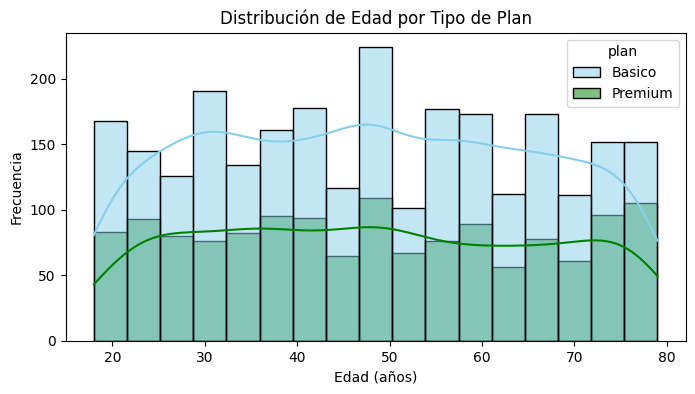

In [36]:
# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Edad por Tipo de Plan')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 

** // RESPUESTAS // **

- **Distribución uniforme y simétrica:** La edad de los clientes se distribuye de manera prácticamente uniforme entre los `18` y `79` años (media y mediana cercanas a `48` años), sin sesgos marcados hacia ningún extremo etario.
- **Comportamiento por plan:** Tanto el plan **Básico** (celeste) como el **Premium** (verde) mantienen exactamente la misma forma a lo largo de todas las edades, conservando la proporción general (~65% Básico vs. ~35% Premium) sin que la edad determine la elección del plan.

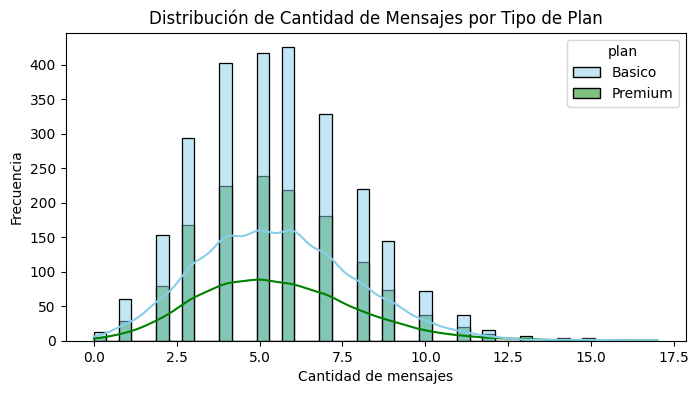

In [37]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Cantidad de Mensajes por Tipo de Plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- ....

** // RESPUESTAS // **

- **Distribución ligeramente sesgada a la derecha:** La mayoría de los usuarios concentra su envío entre `4` y `7` mensajes (mediana de `5` y media de `5.52`), presentando una cola ligera hacia la derecha que alcanza un máximo de `17` mensajes.
- **Comportamiento por plan:** Ambos planes siguen exactamente el mismo patrón de consumo; los usuarios **Premium** no envían más mensajes que los del plan **Básico**, manteniéndose muy por debajo del límite incluido en ambos paquetes (`100` mensajes en Básico y `500` en Premium).

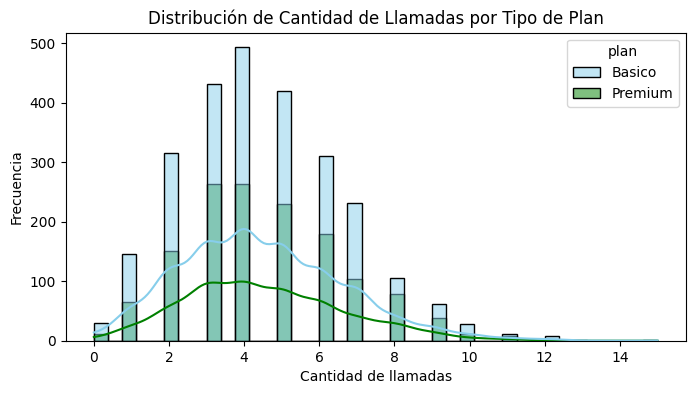

In [38]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Cantidad de Llamadas por Tipo de Plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución ...

 ** // RESPUESTAS // **

- **Distribución sesgada a la derecha:** La mayoría de los clientes realiza entre `3` y `6` llamadas (mediana de `4` y media de `4.48`), con una cola hacia la derecha que alcanza un máximo de `15` llamadas.
- **Comportamiento por plan:** No existe diferencia en la frecuencia de llamadas entre usuarios del plan **Básico** y **Premium**; ambas curvas mantienen exactamente la misma forma y proporción a lo largo de todo el rango.

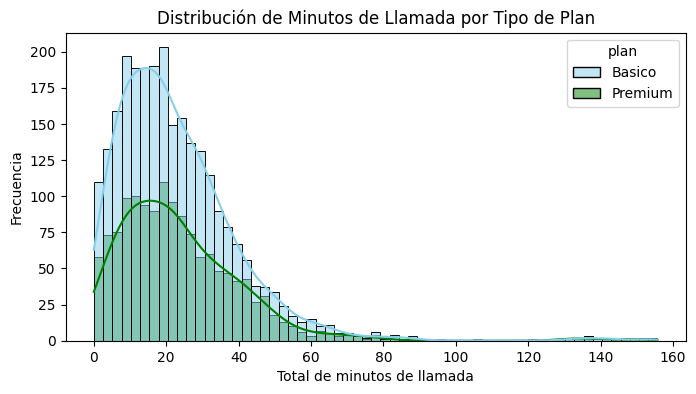

In [39]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Minutos de Llamada por Tipo de Plan')
plt.xlabel('Total de minutos de llamada')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- ...

- **// RESPUESTAS **//

- **Distribución fuertemente sesgada a la derecha:** La mayoría de los clientes consume entre `11` y `31` minutos de llamada (mediana de `19.78` min y media de `23.32` min), presentando una cola larga hacia la derecha que llega hasta `155.69` minutos.

- **Comportamiento por plan:** Ambos planes presentan exactamente la misma forma de distribución; incluso los usuarios de alto consumo en el plan **Básico** superan ocasionalmente los `100` minutos incluidos en su tarifa (generando cobros por excedente), mientras que los usuarios **Premium** se mantienen muy lejos de aprovechar los `600` minutos de su plan.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

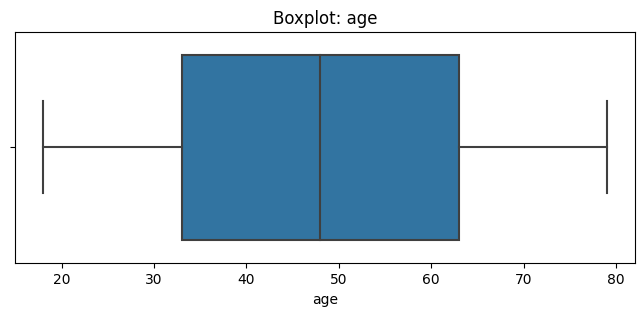

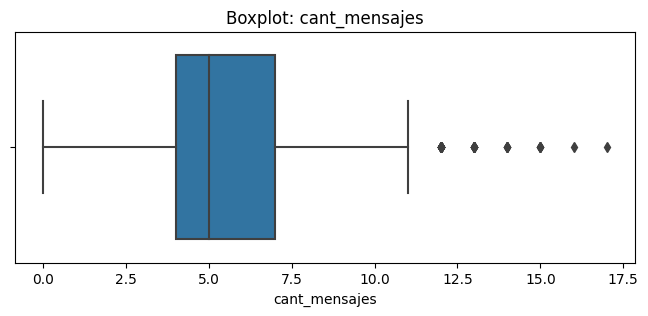

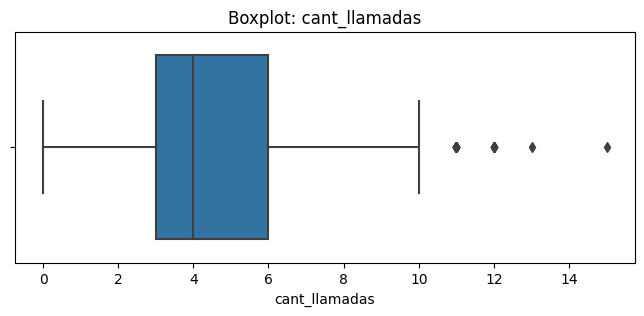

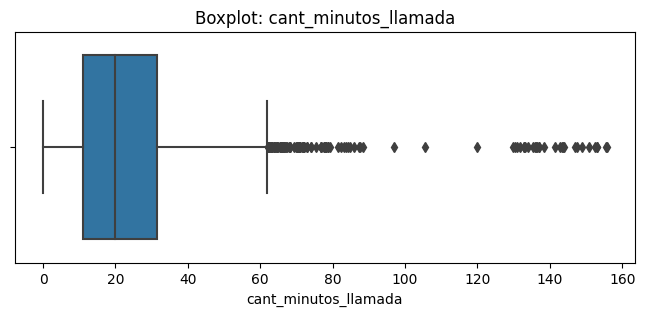

In [53]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...


**// RESPUESTAS //**

- **Age:** **No presenta outliers**; la distribución es completamente simétrica entre el mínimo (`18` años) y el máximo (`79` años), con la mediana centrada en `48` años.
- **cant_mensajes:** **Presenta outliers hacia la derecha** por encima del bigote superior (`11.5` mensajes), alcanzando un valor máximo de `17` mensajes.
- **cant_llamadas:** **Presenta outliers hacia la derecha** por encima del bigote superior (`10.5` llamadas), llegando hasta `15` llamadas.
- **cant_minutos_llamada:** **Presenta una alta concentración de outliers hacia la derecha** a partir de aproximadamente `62` minutos, extendiéndose con valores dispersos hasta `155.69` minutos.
  

In [54]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    outliers_count = (user_profile[col] > upper).sum()
    print(f"{col}: Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}, Límite superior={upper:.2f}, Outliers={outliers_count}")



cant_mensajes: Q1=4.00, Q3=7.00, IQR=3.00, Límite superior=11.50, Outliers=46
cant_llamadas: Q1=3.00, Q3=6.00, IQR=3.00, Límite superior=10.50, Outliers=30
cant_minutos_llamada: Q1=11.12, Q3=31.41, IQR=20.30, Límite superior=61.86, Outliers=109


In [55]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?

** // RESPUESTAS // **

- **cant_mensajes:** **Mantener outliers** (`46` usuarios por encima del límite superior de `11.50` mensajes, hasta un máximo de `17`). Son valores totalmente realistas y posibles dentro del comportamiento normal de telecomunicaciones (muy por debajo de los `100`–`500` mensajes incluidos en los planes), por lo que no representan errores ni fraude.
- **cant_llamadas:** **Mantener outliers** (`30` usuarios por encima del límite superior de `10.50` llamadas, hasta un máximo de `15`). Reflejan usuarios con mayor frecuencia de contacto, un patrón legítimo y natural del negocio que conviene conservar para segmentar correctamente a los clientes activos.
- **cant_minutos_llamada:** **Mantener outliers** (`109` usuarios por encima del límite superior de `61.86` minutos, hasta un máximo de `155.69` minutos). Aunque muestran un sesgo fuerte a la derecha, son consumos de voz perfectamente plausibles (representan clientes *heavy users* que superan los `100` minutos del plan Básico y constituyen una oportunidad comercial clave para migración a plan Premium o cobros por excedente).
  

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [56]:
# Crear columna grupo_uso
def clasificar_uso(row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']
    
    if pd.isna(llamadas) or pd.isna(mensajes):
        return 'Bajo uso'
    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [57]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [58]:
# Crear columna grupo_edad
def clasificar_edad(age):
    if age < 30:
        return 'Joven'
    elif age < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)

In [59]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

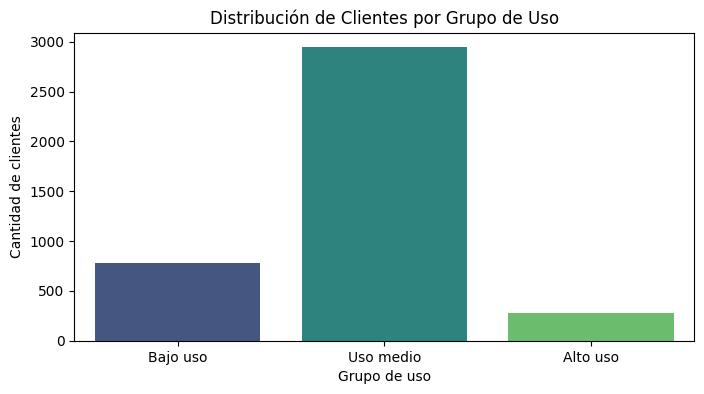

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

Porcentajes:
Uso medio    73.575
Bajo uso     19.475
Alto uso      6.950
Name: grupo_uso, dtype: float64


In [60]:
# Visualización de los segmentos por uso
plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], palette='viridis')
plt.title('Distribución de Clientes por Grupo de Uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de clientes')
plt.show()
print(user_profile['grupo_uso'].value_counts())
print("\nPorcentajes:")
print(user_profile['grupo_uso'].value_counts(normalize=True) * 100)

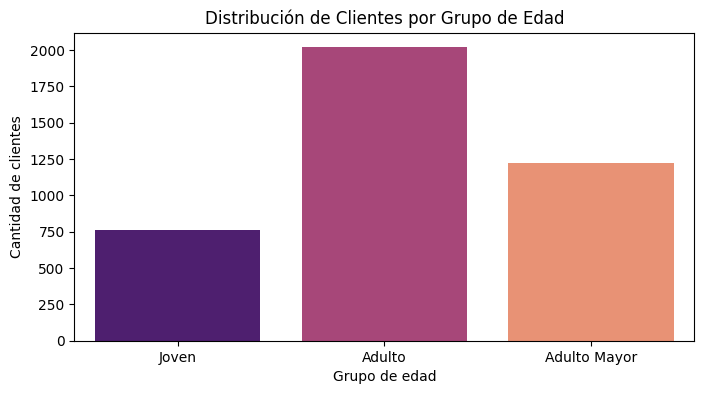

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

Porcentajes:
Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64


In [62]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], palette='magma')
plt.title('Distribución de Clientes por Grupo de Edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de clientes')
plt.show()
print(user_profile['grupo_edad'].value_counts())
print("\nPorcentajes:")
print(user_profile['grupo_edad'].value_counts(normalize=True) * 100)


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- abc
- abc


🔍 **Segmentos por Edad**
- abc
- abc 


📊 **Segmentos por Nivel de Uso**
- abc
- abc


➡️ Esto sugiere que ...


💡 **Recomendaciones**
- abc
- abc

** // RESPUESTAS // ** 

### Análisis ejecutivo

**Problemas detectados en los datos**
- En la base de usuarios (`users`, con 4,000 registros):
  - La columna de ciudad (`city`) tenía 469 datos vacíos (11.73%) y 96 registros con el símbolo "?" (2.40%). En total, 565 clientes (14.13%) no tenían una ciudad válida registrada, por lo que se estandarizaron como valores nulos.
  - En edad (`age`) aparecieron registros con el valor -999 que bajaban artificialmente el promedio a 33.7 años. Se reemplazaron por la mediana real (48 años).
  - En fecha de registro (`reg_date`) se encontraron 40 registros (1%) con fechas del año 2026, lo cual es imposible porque los datos llegan hasta 2024. Se marcaron como nulos para no alterar los tiempos de antigüedad.
  - La fecha de cancelación (`churn_date`) estaba vacía en 3,534 casos (88.35%), lo cual es esperado porque son clientes que siguen activos. Los 466 registros con fecha indican una tasa de cancelación del 11.65%.
- En la base de consumo (`usage`, con 40,000 registros):
  - La fecha (`date`) solo tuvo 50 vacíos (0.12%), sin impacto real en los resultados.
  - Las columnas de duración de llamada (`duration`, 55.19% vacíos) y longitud de mensaje (`length`, 44.74% vacíos) presentan ausencias esperadas por la estructura de la tabla: cuando el registro es un mensaje no hay duración de llamada, y cuando es llamada no hay texto. Por eso se dejaron tal cual.

**Segmentos por edad**
- Adultos (30 a 59 años): Son la mitad exacta de nuestros clientes, con 2,018 usuarios (50.45%), formando la base principal del negocio.
- Adultos mayores (60 años o más): Representan el segundo grupo más grande con 1,222 clientes (30.55%).
- Jóvenes (menores de 30 años): Son el grupo más pequeño, con 760 clientes (19%).
- La edad se reparte de forma muy pareja entre los 18 y 79 años y no influye en qué plan eligen ni en cuánto hablan o escriben. Tanto el plan Básico (64.88%) como el Premium (35.13%) mantienen casi las mismas proporciones en todas las edades.

**Segmentos por nivel de uso**
- Uso medio: Concentra a la gran mayoría con 2,943 clientes (73.58%), quienes hacen entre 5 y 9 llamadas o mensajes, con un consumo típico de 5 mensajes, 4 llamadas y unos 20 minutos hablados.
- Bajo uso: Agrupa a 779 clientes (19.48%) con menos de 5 llamadas y 5 mensajes (incluyendo 1 usuario sin actividad). Este grupo apenas utiliza una fracción mínima de lo que incluye el plan Básico.
- Alto uso: Son 278 clientes (6.95%) que superan las 10 llamadas o mensajes. Aquí aparecen los casos extremos de mayor consumo: 46 usuarios envían más de 11 mensajes (hasta 17), 30 hacen más de 10 llamadas (hasta 15) y 109 hablan más de 62 minutos (llegando hasta 155.7 minutos).

**Qué nos dice esto del negocio**
El uso de llamadas y mensajes es prácticamente igual entre quienes pagan el plan Básico y quienes tienen el Premium. Esto indica que los clientes contratan el plan Premium (20 GB frente a 5 GB del Básico) principalmente por los datos móviles y no por minutos o SMS. Al mismo tiempo, hay un grupo de clientes en el plan Básico que habla más de los 100 minutos incluidos y termina pagando cargos extra, mientras que casi el 20% de los usuarios casi no usa el servicio y corre riesgo de darse de baja.

**Recomendaciones**
- Ofrecer el cambio a Premium a quienes hablan mucho en el plan Básico: Contactar a los clientes de alto uso y a los 109 usuarios con mayor consumo de minutos (especialmente los que pasan de 100 minutos) que aún están en el plan Básico, mostrándoles que migrar al plan Premium 25 USD con 600 minutos, les sale más conveniente que pagar minutos adicionales.
- Crear un plan intermedio: Como el 93% de los usuarios envía menos de 10 mensajes y hace menos de 10 llamadas, conviene lanzar una opción intermedia - por ejemplo, 10 o 12 GB con 150 minutos y 100 mensajes por unos $18 USD- para quienes se quedan cortos con los 5 GB del Básico pero no necesitan todo el paquete Premium.
- Cuidar la retención en los segmentos de bajo uso y adultos mayores: Para los 779 clientes de bajo uso, enviar recordatorios de beneficios o crear una tarifa de entrada más económica para evitar que se vayan por sentir que pagan de más. Para los adultos mayores (30.55% de la cartera), mantener canales de atención sencillos y enfocados en telefonía de voz.
- Mejorar los filtros al registrar clientes nuevos: Configurar reglas en el sistema de captura para impedir que se guarden datos como -999 en la edad, "?" en la ciudad o fechas futuras en el registro, evitando problemas de calidad desde el origen..

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`